# Information-Efficient Calibration of the Heston Model

This notebook investigates whether Fisher-information-based selection can reduce the number of option observations required to calibrate a Heston stochastic volatility model.

A synthetic option market is generated from a Heston model with parameters that evolve gradually over time. Gaussian observation noise is added to the option prices, providing a controlled setting in which the true model parameters are known. An independent set of option contracts is used for out-of-sample evaluation.

The information-efficient calibration works as follows: 
For each option, the sensitivity of its price to the Heston parameters is used to construct a Fisher information matrix. A D-optimal selection procedure then identifies subsets of options that provide complementary information about the model parameters. The calibration, using an information-efficient subset of options, is compared with randomly selected subsets and calibration using the entire set of options.

The analysis focuses on three questions:

1. Does Fisher-information-based selection improve parameter recovery compared with random selection?
2. How does calibration accuracy change as the number of selected options is reduced?
3. Does improved parameter identification translate to more accurate out-of-sample option prices and Greeks?

The aim is not only to minimise the number of observations, but to investigate the trade-off between the amount of market data used for calibration and the quality of the resulting model estimates.

The notebook is structured in the following chapters:
1) Simulation of the options contracts using a Heston model with gradually evolving parameters over time
2) Choice of framework between a fixed Fisher approach using the same subset of market options for each time step, an adaptive Fisher approach updating the optimal subset used for calibration for every time step, and a random selection of the same number of market options to use for recalibration
3) Choice of subset size
4) Evaluation of the framework by out-of-sample options pricing, and Greeks estimation
5) Conclusion

In [30]:
import numpy as np
import matplotlib.pyplot as plt

from pricing.heston_cf import price_heston_call
from pricing.heston_greeks import heston_greeks
from calibration.heston_calib import calibrate_heston
from calibration.fisher import price_sensitivity, scale_fisher_matrix
from calibration.selection import greedy_d_optimal_selection

from calibration.evaluation_simulation import evaluate_subset
from calibration.evaluation_simulation import parameter_rmse, pricing_rmse


In [31]:
import pricing.heston_greeks
import importlib
importlib.reload(pricing.heston_greeks)

<module 'pricing.heston_greeks' from 'C:\\Users\\xprp2\\Documents\\python\\derivatives-research\\src\\pricing\\heston_greeks.py'>

# 1) Simulate market options data over time

Synthetic market options are generated using a Heston model with parameters that evolve gradually over time. This market data is then used to evaluate and optimise the different frameworks.

The market training data consists of 42 options across 7 strikes and 6 maturities. Gaussian noise is added to the option prices to simulate market observation noise.

The Heston parameters evolve linearly from an initial parameter vector to a different final vector over 20 time steps. The framework tries to calibrate these changing parameters with a reduced computation budget. This creates a non-stationary calibration problem in which the most informative observations may change as the underlying model state changes.

Secondly, a separate set of strikes and maturities is generated for each time step with the changing Heston model parameters and is kept entirely out of the calibration data. These observations are used later to evaluate out-of-sample pricing and Greek accuracy.

In [32]:
# Simulated market data
# strikes = np.array([80, 85, 90, 95, 100, 105, 110, 115, 120])
strikes = np.array([80, 85, 90, 95, 100, 105, 110, 120])

# maturities = np.array([0.25, 0.5, 0.6, 0.75, 0.9, 1.0, 1.2, 1.5, 1.7, 2.0])
maturities = np.array([0.25, 0.5, 1.0, 1.5, 2.0])

S0 = 100.0
rate = 0.05
dividend_yield = 0.0

# x dollar of noise to market price
noise_std = 0.1

In [33]:
# Simulated Heston model parameters over time
n_times = 20

theta_start = np.array([0.04, 2.0, 0.04, 0.5, -0.7])
theta_end   = np.array([0.05, 1.75, 0.05, 0.6, -0.6])

true_params_by_time = []

for t in range(n_times):
    alpha = t / (n_times - 1)
    params_t = theta_start + alpha * (theta_end - theta_start)
    true_params_by_time.append({"v0": params_t[0], "kappa": params_t[1], "theta": params_t[2], "ksi": params_t[3], "rho": params_t[4]})

In [34]:
# Simulated prices
market_data_stream = []
rng = np.random.default_rng(5)

times = np.arange(n_times)  # 20 time steps

for i, t in enumerate(times):
    for T in maturities:
        for K in strikes:
            true_price = price_heston_call(S0=S0, K=K, v0=true_params_by_time[i]["v0"], rate=rate, dividend_yield=dividend_yield,
                kappa=true_params_by_time[i]["kappa"], theta=true_params_by_time[i]["theta"], ksi=true_params_by_time[i]["ksi"], rho=true_params_by_time[i]["rho"], T=T)

            noise = rng.normal(0.0, noise_std)
            market_data_stream.append({"time": t, "strike": K, "maturity": T, "true_price": true_price, "price": true_price + noise})

In [35]:
# Test data out of sample
test_strikes = np.array([82, 87, 92, 97, 102, 107, 112, 117, 125])
test_maturities = np.array([0.20, 0.35, 0.60, 0.80, 1.25, 1.50, 2.00])

test_data_t = {}

for t in times:
    test_data_t[t] = []
    for T in test_maturities:
        for K in test_strikes:

            true_price = price_heston_call(S0=S0, K=K, v0=true_params_by_time[t]["v0"], rate=rate, dividend_yield=dividend_yield,
                kappa=true_params_by_time[t]["kappa"], theta=true_params_by_time[t]["theta"],
                ksi=true_params_by_time[t]["ksi"], rho=true_params_by_time[t]["rho"], T=T)
            test_data_t[t].append({"strike": K, "maturity": T, "true_price": true_price})

# 2) Framework optimisation

The objective is to identify a small subset of option observations that contains as much information as possible about the Heston parameters. This subset can then be used to continuously update the model in time using a reduced computational budget while retaining the accuracy of the model. 

For an option with strike \(K\) and maturity \(T\), the price sensitivity to the parameter vector is

$$
J(K,T) =
\frac{\partial C(K,T;\theta)}{\partial \theta}.
$$

Assuming independent price observations with Gaussian noise of standard deviation $\sigma$, the corresponding Fisher information contribution is

$$
I(K,T) =
\frac{J(K,T)^\top J(K,T)}{\sigma^2}.
$$

The information matrices of individual options are combined and a D-optimal greedy selection is used to choose a subset that maximises the determinant of the resulting Fisher information matrix. The use of the determinant takes into account the overall information provided about the whole set of model parameters, favouring subsets that constrain the parameters in complementary directions rather than providing repeated information about the same parameters or combinations.

Because the Heston parameters have different numerical scales, the information matrices are rescaled before performing the selection.

Three calibration strategies are compared:

- Adaptive Fisher selection, where the subset is re-selected every time step as the estimated model parameters evolve.
- Fixed Fisher selection, where the initial information-efficient subset of market options is used throughout and the changing market options of that initial subset are used for recalibration.
- Random selection, where a random selection of market options is used to calibrate the model at every time step, which provides a baseline using the same number of observations.

## First subset calibration

A starting point of the optimal subset at time 0 which is then either used throughout for the fixed Fisher selection, or updated throughout for the adaptive Fisher selection.

In [27]:
# Number of options used at each time step
n_select = 5

# First calibration of Heston
initial_guess = np.array([0.08,  # v0
                        1.0,  # kappa
                        0.08,  # theta
                        0.3,   # ksi
                        -0.3  # rho
                        ])

# Select market points for time 0
market_data_initial = [observation for observation in market_data_stream if observation["time"] == 0]

result = calibrate_heston(initial_guess=initial_guess, market_data=market_data_initial, S0=S0, rate=rate, dividend_yield=dividend_yield)
print('Result', result.x)
estimated_params = result.x
parameter_names = ["v0","kappa","theta","ksi","rho"]

fisher_matrices_t = {}

for T in maturities:
    for K in strikes:
        jacobian = price_sensitivity(params=estimated_params, K=K, T=T, S0=S0, rate=rate, dividend_yield=dividend_yield)
        jacobian = jacobian.reshape(1, -1)
        fisher_matrices_t[(T, K)] = (jacobian.T @ jacobian / noise_std**2)

# Scale fisher information based on the scale of the parameters
scales_t = np.array([estimated_params[0], estimated_params[1], estimated_params[2], estimated_params[3], 1.0])
scaled_fisher_matrices_t = {option: scale_fisher_matrix(I, scales_t) for option, I in fisher_matrices_t.items()}

# Select new subset for next time point
current_selection, _ = greedy_d_optimal_selection(scaled_fisher_matrices_t, n_select=n_select)

fixed_selection = current_selection

Result [ 0.03912973  1.99074092  0.03884166  0.42307208 -0.79396416]


## Different frameworks

### Adaptive Fisher

In [28]:
stream_results_adaptive = []
index_time = 1

initial_guess_adaptive = initial_guess.copy()
for t in times[1:]:

    # Load new data from stream
    market_data_t = [observation for observation in market_data_stream if observation["time"] == t]
    # Select options for recalibration
    selected_options = set(current_selection)
    subset_data = [observation for observation in market_data_t if (observation["maturity"], observation["strike"]) in selected_options]

    # Recalibrate Heston with subset of options

    true_params = np.array([true_params_by_time[t]["v0"], true_params_by_time[t]["kappa"], true_params_by_time[t]["theta"], 
                            true_params_by_time[t]["ksi"], true_params_by_time[t]["rho"]])
    evaluation = evaluate_subset(selected_options=selected_options, calibration_data=subset_data, test_data=test_data_t[t],
        initial_guess=initial_guess_adaptive, true_params=true_params, scales=scales_t, S0=S0, rate=rate,
        dividend_yield=dividend_yield, calibrate_heston=calibrate_heston, price_heston_call=price_heston_call)

    estimated_params_t = evaluation["estimated_params"]
    parameter_error = evaluation["parameter_rmse"]
    price_error = evaluation["test_rmse"]

    stream_results_adaptive.append({"time": t, "estimated_params": estimated_params_t, "true_params": true_params_by_time[index_time],
        "selected_options": current_selection.copy(), "parameter_rmse": parameter_error, "pricing_rmse": price_error})

    # Recalculate Fisher information at new time t
    fisher_matrices_t = {}

    for T in maturities:
        for K in strikes:
            jacobian = price_sensitivity(params=estimated_params_t, K=K, T=T, S0=S0, rate=rate, dividend_yield=dividend_yield)
            jacobian = jacobian.reshape(1, -1)
            fisher_matrices_t[(T, K)] = (jacobian.T @ jacobian / noise_std**2)

    # Scale fisher information based on the scale of the parameters
    # BUT USE ONE SET OF SCALES FROM INITIAL CALIBRATION
    # scales_t = np.array([estimated_params_t[0], estimated_params_t[1], estimated_params_t[2], estimated_params_t[3], 1.0])
    scaled_fisher_matrices_t = {option: scale_fisher_matrix(I, scales_t) for option, I in fisher_matrices_t.items()}

    # Select new subset for next time point
    current_selection, _ = greedy_d_optimal_selection(scaled_fisher_matrices_t, n_select=n_select)
    
    # Update new initial guess for estimating Heston model
    initial_guess_adaptive = estimated_params_t.copy()

    index_time += 1

### Random selection

In [29]:
stream_results_random = []
rng_random = np.random.default_rng(56)
all_options = [(T, K) for T in maturities for K in strikes]
initial_guess_random = initial_guess.copy()
index_time = 1

for t in times[1:]:

    # Load new data from stream
    market_data_t = [observation for observation in market_data_stream if observation["time"] == t]

    # Randomly select n_select options
    current_selection = [all_options[i] for i in rng_random.choice(len(all_options), size=n_select, replace=False)]

    selected_options = set(current_selection)

    subset_data = [observation for observation in market_data_t if (observation["maturity"], observation["strike"]) in selected_options]

    # Recalibrate Heston with random subset
    true_params = np.array([true_params_by_time[t]["v0"], true_params_by_time[t]["kappa"], true_params_by_time[t]["theta"], 
                                true_params_by_time[t]["ksi"], true_params_by_time[t]["rho"]])
    evaluation = evaluate_subset(selected_options=selected_options, calibration_data=subset_data, test_data=test_data_t[t],
        initial_guess=initial_guess_random, true_params=true_params, scales=scales_t, S0=S0, rate=rate,
        dividend_yield=dividend_yield, calibrate_heston=calibrate_heston, price_heston_call=price_heston_call)

    estimated_params_t = evaluation["estimated_params"]
    parameter_error = evaluation["parameter_rmse"]
    price_error = evaluation["test_rmse"]
    
    stream_results_random.append({"time": t, "estimated_params": estimated_params_t, "true_params": true_params_by_time[index_time],
        "selected_options": current_selection.copy(), "parameter_rmse": parameter_error, "pricing_rmse": price_error})
    # Warm start next calibration
    initial_guess_random = estimated_params_t.copy()

    index_time += 1

### Fixed Fisher

In [30]:
stream_results_fixed = []
initial_guess_fixed = initial_guess.copy()
index_time = 1

for t in times[1:]:

    # Load new data from stream
    market_data_t = [observation for observation in market_data_stream if observation["time"] == t]

    # ALWAYS use the same Fisher-selected subset
    selected_options = set(fixed_selection)

    subset_data = [observation for observation in market_data_t if (observation["maturity"], observation["strike"]) in selected_options]

    # Recalibrate Heston with subset of options
    true_params = np.array([true_params_by_time[t]["v0"], true_params_by_time[t]["kappa"], true_params_by_time[t]["theta"], 
                                true_params_by_time[t]["ksi"], true_params_by_time[t]["rho"]])
    evaluation = evaluate_subset(selected_options=selected_options, calibration_data=subset_data, test_data=test_data_t[t],
        initial_guess=initial_guess_fixed, true_params=true_params, scales=scales_t, S0=S0, rate=rate,
        dividend_yield=dividend_yield, calibrate_heston=calibrate_heston, price_heston_call=price_heston_call)

    estimated_params_t = evaluation["estimated_params"]
    parameter_error = evaluation["parameter_rmse"]
    price_error = evaluation["test_rmse"]
    
    stream_results_fixed.append({"time": t, "estimated_params": estimated_params_t, "true_params": true_params_by_time[index_time],
        "selected_options": fixed_selection.copy(), "parameter_rmse": parameter_error, "pricing_rmse": price_error})
    # Warm start next calibration
    initial_guess_fixed = estimated_params_t.copy()
    
    index_time += 1

## Evaluating results


Adaptive Fisher
Mean parameter RMSE:   0.285523
Median parameter RMSE: 0.174722
Final parameter RMSE:  0.120097
Mean OOS pricing RMSE:   0.092030
Median OOS pricing RMSE: 0.081433
Final OOS pricing RMSE:  0.062843

Fixed Fisher
Mean parameter RMSE:   0.302120
Median parameter RMSE: 0.203670
Final parameter RMSE:  0.170348
Mean OOS pricing RMSE:   0.089394
Median OOS pricing RMSE: 0.088952
Final OOS pricing RMSE:  0.063511

Random
Mean parameter RMSE:   3.451404
Median parameter RMSE: 1.208335
Final parameter RMSE:  4.918620
Mean OOS pricing RMSE:   0.242194
Median OOS pricing RMSE: 0.190615
Final OOS pricing RMSE:  0.243455

Relative improvement of Adaptive Fisher
Parameter RMSE vs Random: 91.73%
Parameter RMSE vs Fixed Fisher: 5.49%
OOS pricing RMSE vs Random: 62.00%
OOS pricing RMSE vs Fixed Fisher: -2.95%


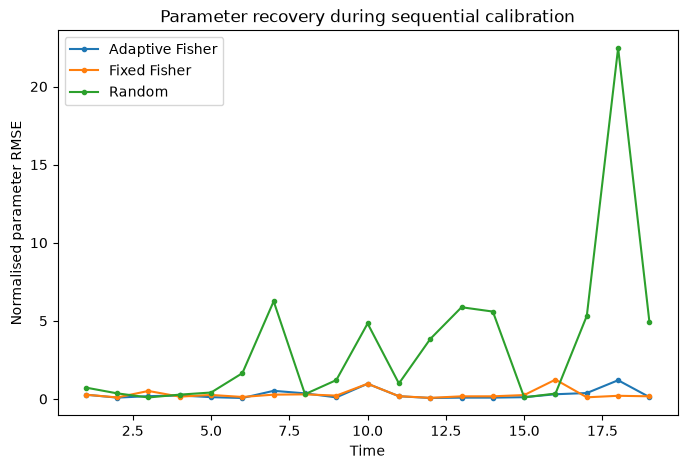

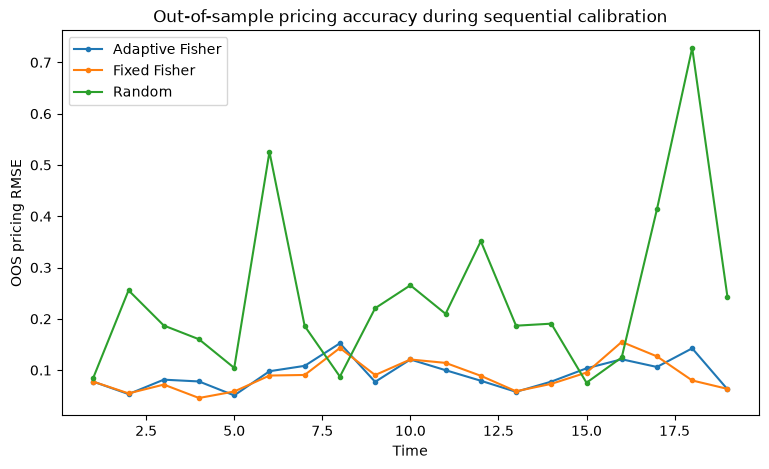

In [ ]:
times_eval = np.array([r["time"] for r in stream_results_adaptive])

adaptive_param_rmse = np.array([r["parameter_rmse"] for r in stream_results_adaptive])
fixed_param_rmse = np.array([r["parameter_rmse"] for r in stream_results_fixed])
random_param_rmse = np.array([r["parameter_rmse"] for r in stream_results_random])

adaptive_price_rmse = np.array([r["pricing_rmse"] for r in stream_results_adaptive])
fixed_price_rmse = np.array([r["pricing_rmse"] for r in stream_results_fixed])
random_price_rmse = np.array([r["pricing_rmse"] for r in stream_results_random])


summary = {"Adaptive Fisher": { "mean_parameter_rmse": np.mean(adaptive_param_rmse),
        "median_parameter_rmse": np.median(adaptive_param_rmse),
        "final_parameter_rmse": adaptive_param_rmse[-1],
        "mean_pricing_rmse": np.mean(adaptive_price_rmse),
        "median_pricing_rmse": np.median(adaptive_price_rmse),
        "final_pricing_rmse": adaptive_price_rmse[-1]},

    "Fixed Fisher": {"mean_parameter_rmse": np.mean(fixed_param_rmse),
        "median_parameter_rmse": np.median(fixed_param_rmse),
        "final_parameter_rmse": fixed_param_rmse[-1],
        "mean_pricing_rmse": np.mean(fixed_price_rmse),
        "median_pricing_rmse": np.median(fixed_price_rmse),
        "final_pricing_rmse": fixed_price_rmse[-1]},

    "Random": {"mean_parameter_rmse": np.mean(random_param_rmse),
        "median_parameter_rmse": np.median(random_param_rmse),
        "final_parameter_rmse": random_param_rmse[-1],
        "mean_pricing_rmse": np.mean(random_price_rmse),
        "median_pricing_rmse": np.median(random_price_rmse),
        "final_pricing_rmse": random_price_rmse[-1]}}


# Print summary
for method, metrics in summary.items():
    print(f"\n{method}")
    print(f"Mean parameter RMSE:   {metrics['mean_parameter_rmse']:.6f}")
    print(f"Median parameter RMSE: {metrics['median_parameter_rmse']:.6f}")
    print(f"Final parameter RMSE:  {metrics['final_parameter_rmse']:.6f}")

    print(f"Mean OOS pricing RMSE:   {metrics['mean_pricing_rmse']:.6f}")
    print(f"Median OOS pricing RMSE: {metrics['median_pricing_rmse']:.6f}")
    print(f"Final OOS pricing RMSE:  {metrics['final_pricing_rmse']:.6f}")


print("\nRelative improvement of Adaptive Fisher")

adaptive_mean_param = summary["Adaptive Fisher"]["mean_parameter_rmse"]
fixed_mean_param = summary["Fixed Fisher"]["mean_parameter_rmse"]
random_mean_param = summary["Random"]["mean_parameter_rmse"]

adaptive_mean_price = summary["Adaptive Fisher"]["mean_pricing_rmse"]
fixed_mean_price = summary["Fixed Fisher"]["mean_pricing_rmse"]
random_mean_price = summary["Random"]["mean_pricing_rmse"]

print(f"Parameter RMSE vs Random: " f"{100 * (random_mean_param - adaptive_mean_param) / random_mean_param:.2f}%")
print(f"Parameter RMSE vs Fixed Fisher: " f"{100 * (fixed_mean_param - adaptive_mean_param) / fixed_mean_param:.2f}%")
print(f"OOS pricing RMSE vs Random: " f"{100 * (random_mean_price - adaptive_mean_price) / random_mean_price:.2f}%")
print(f"OOS pricing RMSE vs Fixed Fisher: " f"{100 * (fixed_mean_price - adaptive_mean_price) / fixed_mean_price:.2f}%")


plt.figure(figsize=(8, 5))
plt.plot(times_eval, adaptive_param_rmse, marker="o", markersize=3, label="Adaptive Fisher")
plt.plot(times_eval, fixed_param_rmse, marker="o", markersize=3, label="Fixed Fisher")
plt.plot(times_eval, random_param_rmse, marker="o", markersize=3, label="Random")
plt.xlabel("Time")
plt.ylabel("Normalised parameter RMSE")
plt.title("Parameter recovery during sequential calibration")
plt.legend()
plt.show()

plt.figure(figsize=(9, 5))
plt.plot(times_eval, adaptive_price_rmse, marker="o", markersize=3, label="Adaptive Fisher")
plt.plot(times_eval, fixed_price_rmse, marker="o", markersize=3, label="Fixed Fisher")
plt.plot(times_eval, random_price_rmse, marker="o", markersize=3, label="Random")
plt.xlabel("Time")
plt.ylabel("OOS pricing RMSE")
plt.title("Out-of-sample pricing accuracy during sequential calibration")
plt.legend()
plt.show()

The sequential experiment compares the three selection strategies using the same number (arbitrary) of calibration observations at each time step.

**Parameter RMSE** measures the accuracy of the recovery of the Heston parameters at that time step. The Fisher-based selection strategies achieve lower parameter RMSE than random selection for most time steps, indicating that the information-efficient subsets allow the Heston parameters to be recovered more accurately using the same number of observations.

Across the simulated timeline, the adaptive Fisher approach reduces the mean parameter RMSE by approximately 92% relative to random selection. The fixed Fisher approach performs very similarly, indicating that the subset identified at the initial time step remains informative as the Heston parameters evolve.

**Out-of-sample pricing RMSE** measures whether the calibrated model generalises to the pricing of out-of-sample strike-maturity combinations at that time step. Both Fisher-based approaches achieve substantially lower pricing RMSE than random selection, indicating that the improved parameter estimation translates into better generalisation to unseen strike–maturity combinations.

Over the simulated timeline, the adaptive Fisher approach reduces the mean out-of-sample pricing RMSE by approximately 62% relative to random selection. This demonstrates that the information-efficient subsets are not only useful for recovering the model parameters, but also for out-of-sample pricing performance based on the calibrated model.

The difference in mean RMSE for the adaptive Fisher approach and the fixed Fisher approach is relatively small (5% for parameter estimation and -3% for options pricing estimation). So we continue with the fixed set Fisher approach as this only requires one initial, computationally expensive, subset selection step.

# 3) Choosing best subset size

The previous experiment fixes the number of selected options in the subset used for recalibration. The next question is how calibration accuracy changes as the number of selected observations in the subset increases.

For each subset size, a Fisher-information-based subset is selected and used for sequential calibration. The resulting parameter RMSE is compared with full-surface calibration, where all market option are used to recalibrate the Heston model.

A 5% tolerance is used to define an information-efficient subset:

$$
\frac{\mathrm{RMSE}_{N}-\mathrm{RMSE}_{\mathrm{full}}}
{\mathrm{RMSE}_{\mathrm{full}}}
\leq 0.05.
$$

The smallest subset satisfying this criterion is taken as the minimum subset size required to achieve performance close to full calibration, while reducing the computational need to recalibrate at every time step.

In [ ]:
subset_sizes = [5, 6, 7, 8, 10, 12, 15, 18, 20, 22, 25, 28, 30, 32, 35, 42]
# subset_sizes = [5, 10, 15, 20, 30, 42, 60, 70, 80, 89]
tolerance = 0.05

all_options = [(T, K) for T in maturities for K in strikes]

# Keep the original initial guess
initial_guess_base = initial_guess.copy()

subset_size_results = {}

for n_select_test in subset_sizes:

    print(f"Running n_select = {n_select_test}...")

    # Select once using the initial Fisher information
    selected_options, _ = greedy_d_optimal_selection(scaled_fisher_matrices_t, n_select=n_select_test)
    selected_options = set(selected_options)
    initial_guess_fixed_test = initial_guess_base.copy()

    time_errors = []

    for t in times[1:]:

        market_data_t = [observation for observation in market_data_stream if observation["time"] == t]
        subset_data = [observation for observation in market_data_t if (observation["maturity"], observation["strike"]) in selected_options]

        true_params = np.array([true_params_by_time[t]["v0"], true_params_by_time[t]["kappa"],
            true_params_by_time[t]["theta"], true_params_by_time[t]["ksi"], true_params_by_time[t]["rho"]])

        # OOS test surface
        test_data_t_subsetexp = []

        for T in test_maturities:
            for K in test_strikes:
                true_price = price_heston_call(S0=S0, K=K, v0=true_params_by_time[t]["v0"], rate=rate, dividend_yield=dividend_yield, kappa=true_params_by_time[t]["kappa"], 
                    theta=true_params_by_time[t]["theta"], ksi=true_params_by_time[t]["ksi"], rho=true_params_by_time[t]["rho"], T=T)
                test_data_t_subsetexp.append({"strike": K, "maturity": T, "true_price": true_price})

        evaluation = evaluate_subset(selected_options=selected_options, calibration_data=subset_data, test_data=test_data_t_subsetexp,
            initial_guess=initial_guess_fixed_test, true_params=true_params, scales=scales_t, S0=S0, rate=rate,
            dividend_yield=dividend_yield, calibrate_heston=calibrate_heston, price_heston_call=price_heston_call)

        time_errors.append(evaluation["parameter_rmse"])

        # Sequential calibration
        initial_guess_fixed_test = evaluation["estimated_params"].copy()

    subset_size_results[n_select_test] = {"selected_options": selected_options, "mean_parameter_rmse": np.mean(time_errors), 
          "median_parameter_rmse": np.median(time_errors), "final_parameter_rmse": time_errors[-1], "time_errors": np.array(time_errors)}

full_rmse = subset_size_results[subset_sizes[-1]]["mean_parameter_rmse"]

# Relative error compared with full calibration
for n in subset_sizes:
    subset_size_results[n]["relative_excess_error"] = (subset_size_results[n]["mean_parameter_rmse"] - full_rmse) / full_rmse

acceptable_sizes = [n for n in subset_sizes if subset_size_results[n]["relative_excess_error"] <= tolerance]

if acceptable_sizes:
    best_subset_size = min(acceptable_sizes)
    print(f"\nBest fixed subset size: {best_subset_size}")
    print(f"Mean OOS RMSE: " f"{subset_size_results[best_subset_size]['mean_parameter_rmse']:.6f}")
    print(f"Relative excess error: " f"{100 * subset_size_results[best_subset_size]['relative_excess_error']:.2f}%")
else:
    best_subset_size = None
    print("\nNo subset satisfies the tolerance.")


print("\nSubset-size results")

for n in subset_sizes:
    result = subset_size_results[n]
    print(f"n = {n:2d} " f"RMSE = {result['mean_parameter_rmse']:.6f} " f"excess = {100 * result['relative_excess_error']:.2f}%")

mean_rmse = [subset_size_results[n]["mean_parameter_rmse"] for n in subset_sizes]
relative_error = [100 * subset_size_results[n]["relative_excess_error"] for n in subset_sizes]

plt.figure(figsize=(9, 5))
plt.plot(subset_sizes, mean_rmse, marker="o")
plt.axhline(full_rmse, linestyle="--", label="Full calibration")
plt.xlabel("Number of selected options")
plt.ylabel("Mean parameter RMSE")
plt.title("Fixed Fisher: parameter accuracy vs subset size")
plt.xticks(subset_sizes)
plt.legend()
plt.show()

plt.figure(figsize=(9, 5))
plt.plot(subset_sizes, relative_error, marker="o")
plt.axhline(100 * tolerance, linestyle="--", label=f"{100 * tolerance:.0f}% tolerance")
plt.axhline(0, linestyle=":")
plt.xlabel("Number of selected options")
plt.ylabel("Excess parameter error vs full calibration (%)")
plt.title("Fixed Fisher: relative parameter error")
plt.xticks(subset_sizes)
plt.legend()
plt.show()

Running n_select = 5...
Running n_select = 6...
Running n_select = 7...
Running n_select = 8...
Running n_select = 10...
Running n_select = 12...
Running n_select = 15...
Running n_select = 18...
Running n_select = 20...
Running n_select = 22...


The resulting curve illustrates the trade-off between the number of market observations and parameter recovery accuracy.

The key result is the smallest subset size that remains within about 25% of the full-calibration error. This provides a direct measure of the reduction in the number of observations required by the information-efficient approach.

In the simulated market, the smallest Fisher-selected subset satisfying the 25% criterion contains 30 options, compared with 90 options in the full surface. Thus, approximately **33%** of the available observations are sufficient to remain within the specified tolerance.

# 4) Evaluation

Parameter recovery alone does not establish whether the selected subset produces a useful calibrated model. The final evaluation considers two quantities: option Greeks and out-of-sample option prices.

The test surface consists of strike-maturity combinations that were not used during calibration.

First, the calibrated parameters are used to price the independent test surface. Pricing RMSE measures how accurately the calibrated model generalises beyond the observations used for estimation.

Second, delta, gamma and vega are calculated from the calibrated parameters and compared with the corresponding Greeks generated using the true Heston parameters.

The comparison is made between fixed Fisher, random selection and full calibration, using the entire surface. Fifteen independent random-selection trials are used to quantify the variability associated with arbitrary subset selection.

## 4.1) Out-of-sample options pricing estimation

In [38]:
# Number of options used at each time step
n_select = 20

# First calibration of Heston
initial_guess = np.array([0.08,  # v0
                        1.0,  # kappa
                        0.08,  # theta
                        0.3,   # ksi
                        -0.3  # rho
                        ])

initial_guess_base = initial_guess.copy()

# Select market points for time 0
market_data_initial = [observation for observation in market_data_stream if observation["time"] == 0]

result = calibrate_heston(initial_guess=initial_guess, market_data=market_data_initial, S0=S0, rate=rate, dividend_yield=dividend_yield)
print('Result', result.x)
estimated_params = result.x
parameter_names = ["v0","kappa","theta","ksi","rho"]

fisher_matrices_t = {}

for T in maturities:
    for K in strikes:
        jacobian = price_sensitivity(params=estimated_params, K=K, T=T, S0=S0, rate=rate, dividend_yield=dividend_yield)
        jacobian = jacobian.reshape(1, -1)
        fisher_matrices_t[(T, K)] = (jacobian.T @ jacobian / noise_std**2)

# Scale fisher information based on the scale of the parameters
scales_t = np.array([estimated_params[0], estimated_params[1], estimated_params[2], estimated_params[3], 1.0])
scaled_fisher_matrices_t = {option: scale_fisher_matrix(I, scales_t) for option, I in fisher_matrices_t.items()}

# Select new subset for next time point
current_selection, _ = greedy_d_optimal_selection(scaled_fisher_matrices_t, n_select=n_select)

fixed_selection = current_selection

Result [ 0.04039937  2.05968275  0.03835867  0.46162618 -0.75417153]


c:\Users\xprp2\Documents\python\derivatives-research\.venv\Lib\site-packages\numpy\_core\fromnumeric.py:3862: RuntimeWarning: Mean of empty slice
  return _methods._mean(a, axis=axis, dtype=dtype,
c:\Users\xprp2\Documents\python\derivatives-research\.venv\Lib\site-packages\numpy\_core\_methods.py:142: RuntimeWarning: invalid value encountered in scalar divide
  ret = ret.dtype.type(ret / rcount)



Mean OOS Pricing RMSE
Fixed Fisher: 4.237198e-02
Random: 5.672554e-02
Full calibration: 3.561040e-02


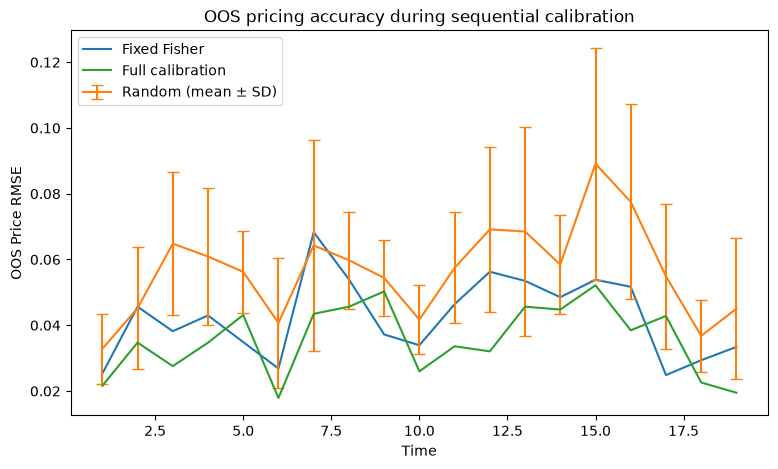

In [39]:
# OOS pricing evaluation

n_random_trials = 10
random_rngs = [np.random.default_rng(31 + i) for i in range(n_random_trials)]
pricing_results = {"fixed": [], "random": [[] for _ in range(n_random_trials)], "full": []}

# Independent initial guesses for each approach
initial_guess_fixed_pricing = initial_guess_base.copy()
initial_guess_random_pricing = [initial_guess_base.copy() for _ in range(n_random_trials)]
initial_guess_full_pricing = initial_guess_base.copy()

for t in times[1:]:
    market_data_t = [observation for observation in market_data_stream if observation["time"] == t]

    true_params = np.array([true_params_by_time[t]["v0"], true_params_by_time[t]["kappa"], true_params_by_time[t]["theta"],
        true_params_by_time[t]["ksi"], true_params_by_time[t]["rho"]])

    # Fixed Fisher
    fixed_options = set(fixed_selection)
    fixed_data = [observation for observation in market_data_t if (observation["maturity"], observation["strike"]) in fixed_options]

    fixed_eval = evaluate_subset(selected_options=fixed_options, calibration_data=fixed_data, test_data=[],
        initial_guess=initial_guess_fixed_pricing, true_params=true_params, scales=scales_t, S0=S0, rate=rate,
        dividend_yield=dividend_yield, calibrate_heston=calibrate_heston, price_heston_call=price_heston_call)

    fixed_params = fixed_eval["estimated_params"]
    initial_guess_fixed_pricing = fixed_params.copy()

    # Calculate OOS prices
    estimated_prices = []
    true_prices = []

    for observation in test_data_t[t]:
        K = observation["strike"]
        T = observation["maturity"]

        estimated = price_heston_call(S0=S0, K=K, v0=fixed_params[0], rate=rate, dividend_yield=dividend_yield,
            kappa=fixed_params[1], theta=fixed_params[2], ksi=fixed_params[3], rho=fixed_params[4], T=T)
        estimated_prices.append(estimated)
        true_prices.append(observation["true_price"])

    pricing_results["fixed"].append({"time": t, "estimated": estimated_prices, "true": true_prices})

    # Random subset
    for trial in range(n_random_trials):
        random_selection = {all_options[i] for i in random_rngs[trial].choice(len(all_options), size=n_select, replace=False)}
        random_data = [observation for observation in market_data_t if (observation["maturity"], observation["strike"]) in random_selection]
        random_eval = evaluate_subset(selected_options=random_selection, calibration_data=random_data, test_data=[],
            initial_guess=initial_guess_random_pricing[trial], true_params=true_params, scales=scales_t, S0=S0,
            rate=rate, dividend_yield=dividend_yield, calibrate_heston=calibrate_heston, price_heston_call=price_heston_call)

        random_params = random_eval["estimated_params"]
        initial_guess_random_pricing[trial] = random_params.copy()

        # Calculate OOS prices
        estimated_prices = []
        true_prices = []

        for observation in test_data_t[t]:

            K = observation["strike"]
            T = observation["maturity"]

            estimated = price_heston_call(S0=S0, K=K, v0=random_params[0], rate=rate, dividend_yield=dividend_yield,
                kappa=random_params[1], theta=random_params[2], ksi=random_params[3], rho=random_params[4], T=T)

            estimated_prices.append(estimated)
            true_prices.append(observation["true_price"])

        pricing_results["random"][trial].append({"time": t, "estimated": estimated_prices, "true": true_prices})

    # Full calibration
    full_options = set(all_options)

    full_eval = evaluate_subset(selected_options=full_options, calibration_data=market_data_t, test_data=[],
        initial_guess=initial_guess_full_pricing, true_params=true_params, scales=scales_t, S0=S0, rate=rate,
        dividend_yield=dividend_yield, calibrate_heston=calibrate_heston, price_heston_call=price_heston_call)

    full_params = full_eval["estimated_params"]
    initial_guess_full_pricing = full_params.copy()


    # Calculate OOS prices
    estimated_prices = []
    true_prices = []

    for observation in test_data_t[t]:

        K = observation["strike"]
        T = observation["maturity"]

        estimated = price_heston_call(S0=S0, K=K, v0=full_params[0], rate=rate, dividend_yield=dividend_yield,
            kappa=full_params[1], theta=full_params[2], ksi=full_params[3], rho=full_params[4], T=T)

        estimated_prices.append(estimated)
        true_prices.append(observation["true_price"])

    pricing_results["full"].append({"time": t, "estimated": estimated_prices, "true": true_prices})


# RMSE 
pricing_rmse = {"fixed": [], "full": []}

for method in ["fixed", "full"]:
    for result in pricing_results[method]:
        estimated = np.array(result["estimated"])
        true = np.array(result["true"])
        pricing_rmse[method].append(np.sqrt(np.mean((estimated - true)**2)))
    pricing_rmse[method] = np.array(pricing_rmse[method])


# Random trials
random_pricing_rmse = []

for trial in range(n_random_trials):
    trial_rmse = []
    for result in pricing_results["random"][trial]:
        estimated = np.array(result["estimated"])
        true = np.array(result["true"])
        trial_rmse.append(np.sqrt(np.mean((estimated - true)**2)))

    random_pricing_rmse.append(trial_rmse)

random_pricing_rmse = np.array(random_pricing_rmse)

random_pricing_mean = np.mean(random_pricing_rmse, axis=0)
random_pricing_sd = np.std(random_pricing_rmse, axis=0, ddof=1)

print("\nMean OOS Pricing RMSE")
print(f"Fixed Fisher: {np.mean(pricing_rmse['fixed']):.6e}")
print(f"Random: {np.mean(random_pricing_mean):.6e}")
print(f"Full calibration: {np.mean(pricing_rmse['full']):.6e}")

# Plot

times_pricing = np.array([result["time"] for result in pricing_results["fixed"]])

plt.figure(figsize=(9, 5))
plt.plot(times_pricing, pricing_rmse["fixed"], label="Fixed Fisher")
plt.errorbar(times_pricing, random_pricing_mean, yerr=random_pricing_sd, capsize=4, label="Random (mean ± SD)")
plt.plot(times_pricing, pricing_rmse["full"], label="Full calibration")
plt.xlabel("Time")
plt.ylabel("OOS Price RMSE")
plt.title("OOS pricing accuracy during sequential calibration")
plt.legend()
plt.show()

In [43]:
fixed_pricing = pricing_rmse["fixed"]
random_pricing = random_pricing_rmse

# Random mean and SD at each time step
random_mean_pricing = np.mean(random_pricing, axis=0)
random_sd_pricing = np.std(random_pricing, axis=0, ddof=1)

# 1. Relative improvement vs mean random RMSE
# Positive = Fixed is better
pricing_relative_improvement = ((random_mean_pricing - fixed_pricing) / random_mean_pricing) * 100

# 2. Win rate against individual random trials
# Fraction of random trials beaten by Fixed
pricing_win_rate = np.mean(fixed_pricing[None, :] < random_pricing, axis=0) * 100

# 3. Standardised advantage
# Positive = Fixed is better
pricing_z_score = np.where(random_sd_pricing > 0, (random_mean_pricing - fixed_pricing) / random_sd_pricing, np.nan)

# 4. Aggregate metrics over time
pricing_mean_relative_improvement = np.mean(pricing_relative_improvement)
pricing_overall_win_rate = np.mean(pricing_win_rate)
pricing_rmse_ratio = (np.mean(fixed_pricing) / np.mean(random_mean_pricing))
pricing_mean_z_score = np.nanmean(pricing_z_score)

print("\nFixed Fisher vs Random — OOS Pricing")
print("=" * 55)
print(f"Mean relative improvement: "f"{pricing_mean_relative_improvement:.2f}%")
print(f"Overall win rate:           "f"{pricing_overall_win_rate:.1f}%")
print(f"Mean RMSE ratio:            "f"{pricing_rmse_ratio:.3f}")
print(f"Mean z-score advantage:     " f"{pricing_mean_z_score:.2f}")

fixed_pricing = pricing_rmse["fixed"]
full_pricing = pricing_rmse["full"]

# Relative improvement of fixed compared to full
fixed_vs_full_improvement = ((full_pricing - fixed_pricing) / full_pricing) * 100

mean_fixed_rmse = np.mean(fixed_pricing)
mean_full_rmse = np.mean(full_pricing)

aggregate_improvement = ((mean_full_rmse - mean_fixed_rmse) / mean_full_rmse) * 100

print("\nFixed Fisher vs Full Calibration — OOS Pricing")
print("=" * 55)
print(f"Mean Fixed Fisher RMSE: {mean_fixed_rmse:.6e}")
print(f"Mean Full Calibration RMSE: {mean_full_rmse:.6e}")
print(f"Mean relative improvement across time: "
      f"{np.mean(fixed_vs_full_improvement):.2f}%")
print(f"Aggregate relative improvement: {aggregate_improvement:.2f}%")
print(f"Mean RMSE ratio (Fixed / Full): "
      f"{mean_fixed_rmse / mean_full_rmse:.3f}")


Fixed Fisher vs Random — OOS Pricing
Mean relative improvement: 24.67%
Overall win rate:           73.2%
Mean RMSE ratio:            0.747
Mean z-score advantage:     0.76

Fixed Fisher vs Full Calibration — OOS Pricing
Mean Fixed Fisher RMSE: 4.237198e-02
Mean Full Calibration RMSE: 3.561040e-02
Mean relative improvement across time: -24.11%
Aggregate relative improvement: -18.99%
Mean RMSE ratio (Fixed / Full): 1.190


- Fixed subset vs random selection: 
The fixed Fisher subset achieves 25% lower out-of-sample pricing RMSE than random selection, despite using the same reduced number of calibration observations. Fixed Fisher also outperforms random selection in 73.2% of comparisons across the simulated calibration sequence. This suggests that the benefits of Fisher information-based selection extend beyond parameter recovery to the pricing of unseen strike–maturity combinations.

- Fixed subset vs full calibration: 
The fixed Fisher subset achieves an out-of-sample pricing RMSE of 4.2e-2, compared with 3.6e-2 when calibrating to the full option surface. The selected subset performs within 24% of the full-surface calibration's pricing accuracy while using only 20/42 (~50%) of the available observations. These results suggest that information-guided selection can reduce the number of calibration observations without a proportionate loss in out-of-sample pricing performance.

## 4.2) Greeks estimation

The next experiment evaluates the calibrated models on:

- Delta,
- Gamma,
- Vega.

Three calibration strategies are compared:

- Fixed Fisher subset,
- Random subsets of the same size,
- Full calibration using all available options.

Random subset selection uses fifteen independent trials of option choices to quantify the variability of the choice in options.

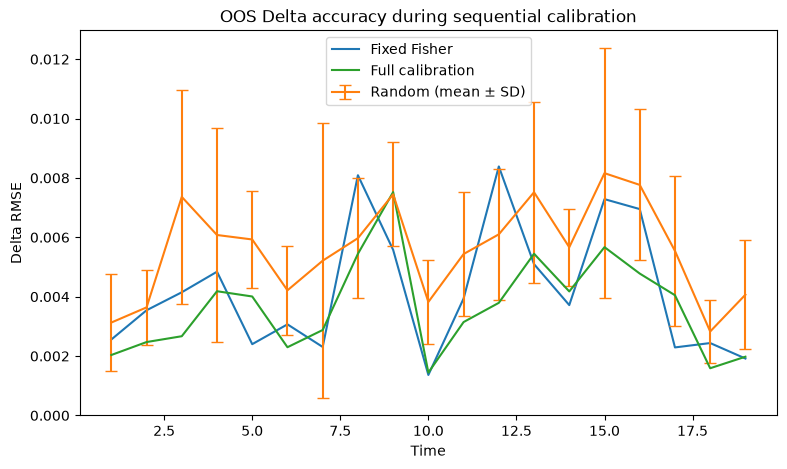

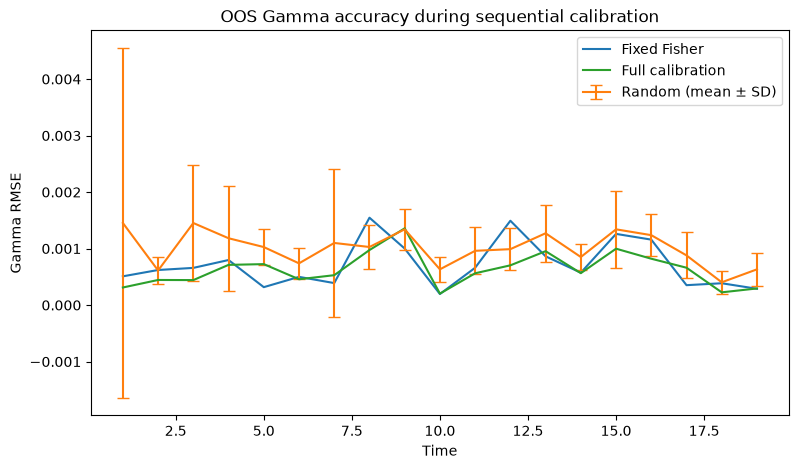

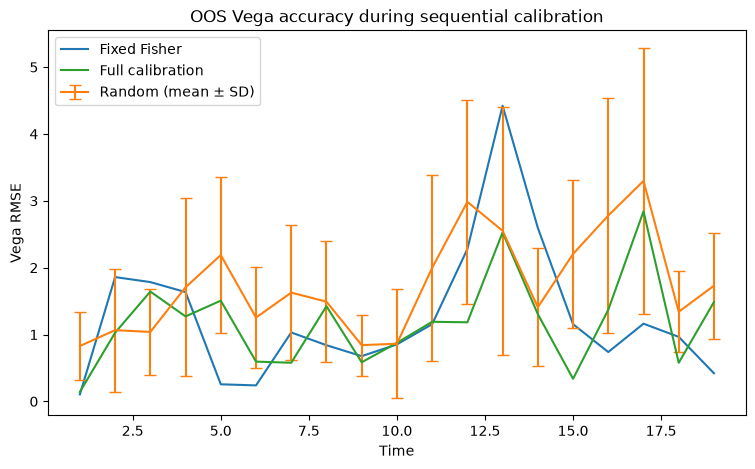

In [41]:
n_select = 20

n_random_trials = 10
random_rngs = [np.random.default_rng(31 + i) for i in range(n_random_trials)]
# pricing_results = {"fixed": [], "random": [[] for _ in range(n_random_trials)], "full": []}

all_options = [(T, K) for T in maturities for K in strikes]

# Keep independent initial guesses for each approach
initial_guess_fixed_greeks = initial_guess_base.copy()
# initial_guess_random_greeks = initial_guess_base.copy()
initial_guess_random_greeks = [initial_guess_base.copy() for _ in range(n_random_trials)]
initial_guess_full_greeks = initial_guess_base.copy()

true_greeks = {}

for t in times[1:]:
    true_params = np.array([true_params_by_time[t]["v0"], true_params_by_time[t]["kappa"], 
            true_params_by_time[t]["theta"], true_params_by_time[t]["ksi"], true_params_by_time[t]["rho"]])

    for T in test_maturities:
        for K in test_strikes:
            true_greeks[(t, T, K)] = heston_greeks(params=true_params, S0=S0, K=K, T=T, rate=rate,
                dividend_yield=dividend_yield, price_heston_call=price_heston_call)

# greek_results = {"fixed": [], "random": [], "full": []}
greek_results = {"fixed": [], "random": [[] for _ in range(n_random_trials)], "full": []}

for t in times[1:]:
    market_data_t = [observation for observation in market_data_stream if observation["time"] == t]

    # Fixed set approach
    fixed_options = set(fixed_selection)
    fixed_data = [observation for observation in market_data_t if (observation["maturity"], observation["strike"]) in fixed_options]

    fixed_eval = evaluate_subset(selected_options=fixed_options, calibration_data=fixed_data, test_data=[],
        initial_guess=initial_guess_fixed_greeks, true_params=np.array([true_params_by_time[t]["v0"], true_params_by_time[t]["kappa"],  true_params_by_time[t]["theta"], true_params_by_time[t]["ksi"], true_params_by_time[t]["rho"]]),
        scales=scales_t, S0=S0, rate=rate, dividend_yield=dividend_yield, calibrate_heston=calibrate_heston, price_heston_call=price_heston_call)

    fixed_params = fixed_eval["estimated_params"]
    initial_guess_fixed_greeks = fixed_params.copy()


    # Random approach
    for trial in range(n_random_trials):

        random_selection = {all_options[i] for i in random_rngs[trial].choice(len(all_options), size=n_select, replace=False)}
        random_data = [observation for observation in market_data_t if (observation["maturity"], observation["strike"]) in random_selection]
        random_eval = evaluate_subset(selected_options=random_selection, calibration_data=random_data, test_data=[],
            initial_guess=initial_guess_random_greeks[trial], true_params=np.array([true_params_by_time[t]["v0"], true_params_by_time[t]["kappa"], true_params_by_time[t]["theta"], true_params_by_time[t]["ksi"], true_params_by_time[t]["rho"]]),
            scales=scales_t, S0=S0, rate=rate, dividend_yield=dividend_yield, calibrate_heston=calibrate_heston, price_heston_call=price_heston_call)

        random_params = random_eval["estimated_params"]
        initial_guess_random_greeks[trial] = random_params.copy()

        estimated_greeks = []
        true_greeks_t = []

        for T in test_maturities:
            for K in test_strikes:
                estimated = heston_greeks(params=random_params, S0=S0, K=K, T=T, rate=rate, dividend_yield=dividend_yield, price_heston_call=price_heston_call)
                true = true_greeks[(t, T, K)]

                estimated_greeks.append(estimated)
                true_greeks_t.append(true)

        greek_results["random"][trial].append({"time": t, "estimated": estimated_greeks, "true": true_greeks_t})

    # random_selection = {all_options[i] for i in rng_random.choice(len(all_options), size=n_select, replace=False)}
    # random_data = [observation for observation in market_data_t if (observation["maturity"], observation["strike"]) in random_selection]
    # random_eval = evaluate_subset(selected_options=random_selection, calibration_data=random_data, test_data=[],
    #     initial_guess=initial_guess_random_greeks, true_params=np.array([true_params_by_time[t]["v0"], true_params_by_time[t]["kappa"], true_params_by_time[t]["theta"], true_params_by_time[t]["ksi"], true_params_by_time[t]["rho"]]),
    #     scales=scales_t, S0=S0, rate=rate, dividend_yield=dividend_yield, calibrate_heston=calibrate_heston, price_heston_call=price_heston_call)

    # random_params = random_eval["estimated_params"]
    # initial_guess_random_greeks = random_params.copy()

    # Full set approach
    full_options = set(all_options)

    full_eval = evaluate_subset(selected_options=full_options, calibration_data=market_data_t, test_data=[], initial_guess=initial_guess_full_greeks,
        true_params=np.array([ true_params_by_time[t]["v0"], true_params_by_time[t]["kappa"], true_params_by_time[t]["theta"], true_params_by_time[t]["ksi"], true_params_by_time[t]["rho"]]),
        scales=scales_t, S0=S0, rate=rate, dividend_yield=dividend_yield, calibrate_heston=calibrate_heston, price_heston_call=price_heston_call)

    full_params = full_eval["estimated_params"]
    initial_guess_full_greeks = full_params.copy()

    for method, params in [("fixed", fixed_params), ("random", random_params), ("full", full_params)]:
        estimated_greeks = []
        true_greeks_t = []

        for T in test_maturities:
            for K in test_strikes:

                estimated = heston_greeks(params=params, S0=S0, K=K, T=T, rate=rate, dividend_yield=dividend_yield, price_heston_call=price_heston_call)
                true = true_greeks[(t, T, K)]

                estimated_greeks.append(estimated)
                true_greeks_t.append(true)

        greek_results[method].append({"time": t, "estimated": estimated_greeks, "true": true_greeks_t})

greek_rmse = {"fixed": {}, "full": {}}

for method in ["fixed", "full"]:
    for greek in ["delta", "gamma", "vega"]:
        errors_by_time = []
        for result in greek_results[method]:
            estimated = np.array([x[greek] for x in result["estimated"]])
            true = np.array([x[greek] for x in result["true"]])

            errors_by_time.append(np.sqrt(np.mean((estimated - true)**2)))

        greek_rmse[method][greek] = np.array(errors_by_time)


# Random: calculate RMSE for each of the 5 trials
random_rmse = {}

for greek in ["delta", "gamma", "vega"]:
    trial_rmses = []
    for trial in range(n_random_trials):
        errors_by_time = []
        for result in greek_results["random"][trial]:

            estimated = np.array([x[greek] for x in result["estimated"]])
            true = np.array([x[greek] for x in result["true"]])

            errors_by_time.append(np.sqrt(np.mean((estimated - true)**2)))

        trial_rmses.append(errors_by_time)
    random_rmse[greek] = np.array(trial_rmses)

random_mean = {greek: np.mean(random_rmse[greek], axis=0) for greek in random_rmse}
random_sd = {greek: np.std(random_rmse[greek], axis=0, ddof=1) for greek in random_rmse}

times_greek = np.array([r["time"] for r in greek_results["fixed"]])
for greek in ["delta", "gamma", "vega"]:
    plt.figure(figsize=(9, 5))
    plt.plot(times_greek, greek_rmse["fixed"][greek], label="Fixed Fisher")
    # plt.plot(times_greek, greek_rmse["random"][greek], label="Random")
    plt.errorbar(times_greek, random_mean[greek], yerr=random_sd[greek], capsize=4, label="Random (mean ± SD)")
    plt.plot(times_greek, greek_rmse["full"][greek], label="Full calibration")
    plt.xlabel("Time")
    plt.ylabel(f"{greek.capitalize()} RMSE")
    plt.title(f"OOS {greek.capitalize()} accuracy during sequential calibration")
    plt.legend()
    plt.show()

In [ ]:
comparison_metrics = {}

for greek in ["delta", "gamma", "vega"]:

    fixed = greek_rmse["fixed"][greek]
    random = random_rmse[greek]          # shape: (n_trials, n_times)
    random_mean_t = random_mean[greek]
    random_sd_t = random_sd[greek]

    # 1. Relative improvement vs mean random RMSE
    # Positive = Fixed is better
    relative_improvement = ((random_mean_t - fixed) / random_mean_t) * 100

    # 2. Win rate: fraction of random trials beaten by Fixed
    win_rate = np.mean(fixed[None, :] < random, axis=0) * 100

    # 3. Standardised advantage relative to random distribution
    # Positive = Fixed is better
    z_score = (random_mean_t - fixed) / random_sd_t

    # Avoid division problems if random SD happens to be zero
    z_score = np.where(random_sd_t > 0, z_score, np.nan)

    # 4. Aggregate metrics over all time steps
    mean_relative_improvement = np.mean(relative_improvement)
    overall_win_rate = np.mean(win_rate)

    # Ratio < 1 means Fixed has lower RMSE
    rmse_ratio = np.mean(fixed) / np.mean(random_mean_t)

    comparison_metrics[greek] = {"relative_improvement": relative_improvement, "win_rate": win_rate, "z_score": z_score,
     "mean_relative_improvement": mean_relative_improvement, "overall_win_rate": overall_win_rate, "rmse_ratio": rmse_ratio}

# print("Fixed Fisher vs Random")

# for greek in ["delta", "gamma", "vega"]:

#     m = comparison_metrics[greek]

#     print(f"\n{greek.upper()}")
#     print(f"Mean relative improvement: {m['mean_relative_improvement']:.2f}%")
#     print(f"Overall win rate:           {m['overall_win_rate']:.1f}%")
#     print(f"Mean RMSE ratio:            {m['rmse_ratio']:.3f}")
#     print(f"Mean z-score advantage:     {np.nanmean(m['z_score']):.2f}")

Fixed Fisher vs Random

DELTA
Mean relative improvement: 25.50%
Overall win rate:           71.6%
Mean RMSE ratio:            0.755
Mean z-score advantage:     0.65

GAMMA
Mean relative improvement: 28.25%
Overall win rate:           66.8%
Mean RMSE ratio:            0.709
Mean z-score advantage:     0.58

VEGA
Mean relative improvement: 21.75%
Overall win rate:           61.1%
Mean RMSE ratio:            0.728
Mean z-score advantage:     0.44


In [45]:
for greek in ["delta", "gamma", "vega"]:

    fixed_greek = greek_rmse["fixed"][greek]
    random_greek = random_rmse[greek]
    full_greek = greek_rmse["full"][greek]

    random_mean_greek = np.mean(random_greek, axis=0)
    random_sd_greek = np.std(random_greek, axis=0, ddof=1)

    # Fixed vs random

    relative_improvement = np.where(random_mean_greek > 0, (random_mean_greek - fixed_greek) / random_mean_greek * 100, np.nan)
    win_rate = np.mean(fixed_greek[None, :] < random_greek, axis=0) * 100
    z_score = np.divide(random_mean_greek - fixed_greek, random_sd_greek, out=np.full_like(random_mean_greek, np.nan, dtype=float), where=random_sd_greek > 0)
    
    mean_relative_improvement = np.nanmean(relative_improvement)
    overall_win_rate = np.mean(win_rate)
    rmse_ratio = np.mean(fixed_greek) / np.mean(random_mean_greek)
    mean_z_score = np.nanmean(z_score)

    print(f"\n{'-' * 60}")
    print(f"{greek.upper()} — Fixed Fisher vs Random")
    print(f"Mean relative improvement: {mean_relative_improvement:.2f}%")
    print(f"Overall win rate:          {overall_win_rate:.1f}%")
    print(f"Mean RMSE ratio:            {rmse_ratio:.3f}")
    print(f"Mean z-score advantage:     {mean_z_score:.2f}")

    # Fixed vs full

    fixed_vs_full_improvement = np.where(full_greek > 0, (full_greek - fixed_greek) / full_greek * 100, np.nan)
    mean_fixed_rmse = np.mean(fixed_greek)
    mean_full_rmse = np.mean(full_greek)
    aggregate_improvement = ((mean_full_rmse - mean_fixed_rmse) / mean_full_rmse * 100 if mean_full_rmse > 0 else np.nan)
    mean_rmse_ratio_full = (mean_fixed_rmse / mean_full_rmse if mean_full_rmse > 0 else np.nan)

    print(f"\n{greek.upper()} — Fixed Fisher vs Full Calibration")
    print(f"Mean Fixed Fisher RMSE:       {mean_fixed_rmse:.6e}")
    print(f"Mean Full Calibration RMSE:   {mean_full_rmse:.6e}")
    print(f"Mean relative improvement:    "
          f"{np.nanmean(fixed_vs_full_improvement):.2f}%")
    print(f"Aggregate relative improvement: {aggregate_improvement:.2f}%")
    print(f"Mean RMSE ratio (Fixed / Full): {mean_rmse_ratio_full:.3f}")


------------------------------------------------------------
DELTA — Fixed Fisher vs Random
Mean relative improvement: 25.50%
Overall win rate:          71.6%
Mean RMSE ratio:            0.755
Mean z-score advantage:     0.65

DELTA — Fixed Fisher vs Full Calibration
Mean Fixed Fisher RMSE:       4.205852e-03
Mean Full Calibration RMSE:   3.661611e-03
Mean relative improvement:    -17.93%
Aggregate relative improvement: -14.86%
Mean RMSE ratio (Fixed / Full): 1.149

------------------------------------------------------------
GAMMA — Fixed Fisher vs Random
Mean relative improvement: 28.25%
Overall win rate:          66.8%
Mean RMSE ratio:            0.709
Mean z-score advantage:     0.58

GAMMA — Fixed Fisher vs Full Calibration
Mean Fixed Fisher RMSE:       7.144761e-04
Mean Full Calibration RMSE:   6.286940e-04
Mean relative improvement:    -17.43%
Aggregate relative improvement: -13.64%
Mean RMSE ratio (Fixed / Full): 1.136

---------------------------------------------------------

Greeks depend on the local shape of the option-pricing surface and are thus a more sensitive test of calibration quality than option prices alone. The results show that the fixed Fisher subset generally provides more accurate Greek estimates than random selection, demonstrating that the information-efficient subset retains useful information about the local behaviour of the pricing surface.

- **Fixed subset vs random selection**:
The fixed Fisher subset achieves 22-28% lower Greeks estimation RMSE than random selection, despite using the same reduced number of calibration observations. Fixed Fisher also outperforms random selection in 61-72% of comparisons across the simulated calibration sequence. This shows that the benefits of Fisher information-based selection also extend to the estimation of the Greeks.

- **Fixed subset vs full calibration**: 
Comparing the fixed subset Greeks estimation RMSE to the Greeks estimation from using the full options market to calibrate shows the fixed subset stays between 17-21% of the full calibration RMSE. The fixed subset only uses 20/42 (~50%) of the available observations. These results suggest that information-guided selection can also serve to estimate Greeks within 17-21% RMSE while reducing the number of calibration observations to about half.

However, the increase in RMSE compared to the calibration using the full options market is higher and less consistent for Greeks estimation and out-of-sample pricing than for parameter recovery. This suggests that a subset that is sufficient for recovering the Heston parameters is not necessarily optimal for estimating all prices and pricing sensitivities.

Potential improvements to the framework could include a subset selection method prioritising precision in the greeks over precision in the Heston parameters.

Overall, the experiments therefore distinguish between three related but different objectives: recovering the underlying Heston parameters, reproducing option prices, and estimating risk sensitivities. Fisher-efficient selection performs particularly strongly for parameter recovery, while the results for out-of-sample pricing and Greeks demonstrate the additional sensitivity of risk measures to the choice of calibration observations. 

# 5) Conclusions

The project investigated whether Fisher-information-based experimental design can reduce the amount of option-market data required to calibrate a time-varying Heston model.

The experiments support four main conclusions.

**1. Information-efficient subsets can reduce calibration data**

Fisher-based selection identifies a relatively small subset of the available strike-maturity surface that can recover the Heston parameters with accuracy close to full-surface calibration.

The subset-size experiment provides a quantitative estimate of the amount of data that can be removed before parameter calibration accuracy deteriorates below a set threshold.

**2. The choice of options matters**

Random subsets of the same size provide a useful baseline. Comparing them with Fisher-selected subsets tests whether information-aware selection is able to outperform a random selection of market data. The evaluation experiments identify the improvement of an informative subset over a random subset for out-of-sample pricing and greeks estimation.

**3. Adaptation tests whether the information set is state-dependent**

The Heston parameters evolve through time in the simulated market. Updating the Fisher-optimal subset therefore tests whether the most informative options change as the model state changes.

The difference between Adaptive and Fixed Fisher provides evidence about whether recalculating the information set is worthwhile. From section 2 in this notebook, the results seemed inconclusive on the effectiveness of updating the subset continuously. As such, a fixed Fisher subset is used throughout the rest of the experiments to reduce the computational cost of continuous subset updates.

**4. Price accuracy and Greek accuracy are different objectives**

The OOS pricing and Greek experiments show that good parameter recovery does not necessarily guarantee equally good quantities such as out-of-sample pricing and Delta, Gamma and Vega.

This highlights an important limitation of using parameter Fisher information as the sole selection criterion. For applications where accurate Greeks are the primary objective, a future extension could select options according to their expected information about the quantity of interest rather than the determinant of the parameter Fisher information matrix alone.

**Overall**

The central result of the project is not only that fewer options can be used for Heston calibration. It also highlights that only reducing the number of calibration observations is not sufficient: which observations are selected is important for maintaining model generalisation. Here, Fisher information and the D-optimality greedy selection are used in an **information-efficient calibration framework** to select options according to their expected information content.

The framework provides a bridge between statistical experimental design and practical derivatives calibration, while also illustrating the distinction between parameter identification, pricing accuracy and risk-measure accuracy.